
# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

## Đề tài
Ứng dụng K-Means trong phân nhóm sinh viên dựa trên hành vi học tập nhằm hỗ trợ cá nhân hóa phương pháp học tập.

## 1. Mục tiêu phân tích

- Tìm hiểu cấu trúc và đặc điểm bộ dữ liệu sinh viên.
- Kiểm tra chất lượng dữ liệu sau tiền xử lý.
- Phân tích các đặc trưng liên quan đến hành vi học tập.
- Khám phá sự khác biệt giữa các nhóm sinh viên.
- Đề xuất các đặc trưng phù hợp để xây dựng mô hình K-Means.

## 2. Thông tin dữ liệu

- Nguồn dữ liệu: Kaggle.
- Số bản ghi: 10.000 sinh viên.
- Số thuộc tính ban đầu: 21.
- Số thuộc tính sau tiền xử lý: 19.
- File dữ liệu sử dụng: data/processed/clean_data.csv.


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Hỗ trợ chạy notebook từ thư mục gốc hoặc notebooks
ROOT = Path.cwd()
if not (ROOT / "data" / "processed" / "clean_data.csv").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "processed" / "clean_data.csv"

df = pd.read_csv(DATA_PATH)

print("Kích thước dữ liệu:", df.shape)
print("\nDanh sách thuộc tính:")
print(df.columns.tolist())

display(df.head())


Kích thước dữ liệu: (10000, 19)

Danh sách thuộc tính:
['Student_ID', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Department', 'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Total_Score', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'science_score']


,Student_ID,First_Name,Last_Name,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Total_Score,test_preparation_course,math_score,reading_score,writing_score,science_score
0,S1000,Omar,Williams,Female,22.0,Engineering,52.29,55.03,57.82,84.22,74.06,3.99,85.90,56.09,1.0,89,38.0,85.0,26.0
1,S1001,Maria,Brown,Male,18.0,Engineering,97.27,97.23,45.80,74.32,94.24,8.32,55.65,50.64,0.0,65,100.0,67.0,96.0
2,S1002,Ahmed,Jones,Male,24.0,Business,57.19,67.05,93.68,67.70,85.70,5.05,73.79,70.30,0.0,10,99.0,97.0,58.0
3,S1003,Omar,Williams,Female,24.0,Mathematics,95.15,47.79,80.63,66.06,93.51,6.54,92.12,61.63,1.0,22,51.0,41.0,84.0
4,S1004,John,Smith,Female,23.0,CS,54.18,46.59,78.89,96.85,83.70,5.97,68.42,66.13,1.0,26,58.0,64.0,65.0



# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

## Đề tài
Ứng dụng K-Means trong phân nhóm sinh viên dựa trên hành vi học tập nhằm hỗ trợ cá nhân hóa phương pháp học tập.

## 1. Mục tiêu phân tích

- Tìm hiểu cấu trúc và đặc điểm bộ dữ liệu sinh viên.
- Kiểm tra chất lượng dữ liệu sau tiền xử lý.
- Phân tích các đặc trưng liên quan đến hành vi học tập.
- Khám phá sự khác biệt giữa các nhóm sinh viên.
- Đề xuất các đặc trưng phù hợp để xây dựng mô hình K-Means.

## 2. Thông tin dữ liệu

- Nguồn dữ liệu: Kaggle.
- Số bản ghi: 10.000 sinh viên.
- Số thuộc tính ban đầu: 21.
- Số thuộc tính sau tiền xử lý: 19.
- File dữ liệu sử dụng: data/processed/clean_data.csv.


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Hỗ trợ chạy notebook từ thư mục gốc hoặc notebooks
ROOT = Path.cwd()
if not (ROOT / "data" / "processed" / "clean_data.csv").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "processed" / "clean_data.csv"

df = pd.read_csv(DATA_PATH)

print("Kích thước dữ liệu:", df.shape)
print("\nDanh sách thuộc tính:")
print(df.columns.tolist())

display(df.head())


Kích thước dữ liệu: (10000, 19)

Danh sách thuộc tính:
['Student_ID', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Department', 'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Total_Score', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'science_score']


,Student_ID,First_Name,Last_Name,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Total_Score,test_preparation_course,math_score,reading_score,writing_score,science_score
0,S1000,Omar,Williams,Female,22.0,Engineering,52.29,55.03,57.82,84.22,74.06,3.99,85.90,56.09,1.0,89,38.0,85.0,26.0
1,S1001,Maria,Brown,Male,18.0,Engineering,97.27,97.23,45.80,74.32,94.24,8.32,55.65,50.64,0.0,65,100.0,67.0,96.0
2,S1002,Ahmed,Jones,Male,24.0,Business,57.19,67.05,93.68,67.70,85.70,5.05,73.79,70.30,0.0,10,99.0,97.0,58.0
3,S1003,Omar,Williams,Female,24.0,Mathematics,95.15,47.79,80.63,66.06,93.51,6.54,92.12,61.63,1.0,22,51.0,41.0,84.0
4,S1004,John,Smith,Female,23.0,CS,54.18,46.59,78.89,96.85,83.70,5.97,68.42,66.13,1.0,26,58.0,64.0,65.0



## 3. Thống kê mô tả dữ liệu

Mục tiêu:
- Xác định số lượng sinh viên và thuộc tính.
- Phân biệt thuộc tính định lượng và định tính.
- Phân tích giá trị trung bình, độ lệch chuẩn, giá trị nhỏ nhất và lớn nhất.
- Kiểm tra dữ liệu thiếu và dữ liệu trùng lặp.


In [12]:

# 3.1. Thông tin tổng quan
print("Số sinh viên:", df.shape[0])
print("Số thuộc tính:", df.shape[1])

print("\nKiểu dữ liệu:")
display(df.dtypes.to_frame(name="Data Type"))

# 3.2. Thống kê các thuộc tính định lượng
print("\nThống kê mô tả:")
display(df.describe().T.round(2))

# 3.3. Kiểm tra dữ liệu thiếu
print("\nSố giá trị thiếu theo từng cột:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# 3.4. Kiểm tra dữ liệu trùng lặp
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print("Số mã sinh viên trùng:", df["Student_ID"].duplicated().sum())


Số sinh viên: 10000
Số thuộc tính: 19

Kiểu dữ liệu:


,Data Type
Student_ID,str
First_Name,str
Last_Name,str
Gender,str
Age,float64
Department,str
Attendance (%),float64
Midterm_Score,float64
Final_Score,float64
Assignments_Avg,float64



Thống kê mô tả:


,count,mean,std,min,25%,50%,75%,max
Age,10000.0,20.77,1.87,18.00,19.00,21.00,22.00,24.00
Attendance (%),10000.0,75.14,14.39,50.01,62.85,75.29,87.41,100.00
Midterm_Score,10000.0,70.37,17.29,40.00,55.44,70.59,85.24,99.98
Final_Score,10000.0,69.84,17.29,40.00,54.87,69.92,84.84,99.98
Assignments_Avg,10000.0,74.90,14.37,50.00,62.42,74.85,87.21,99.98
Quizzes_Avg,10000.0,74.84,14.43,50.03,62.36,74.72,87.35,99.96
Participation_Score,10000.0,5.01,2.89,0.00,2.49,5.02,7.52,10.00
Projects_Score,10000.0,75.28,14.43,50.01,62.81,75.40,87.86,100.00
Total_Score,10000.0,75.03,14.34,50.02,62.84,75.06,87.48,99.99
test_preparation_course,10000.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00



Số giá trị thiếu theo từng cột:


,Missing Values
Student_ID,0
First_Name,0
Last_Name,0
Gender,0
Age,0
Department,0
Attendance (%),0
Midterm_Score,0
Final_Score,0
Assignments_Avg,0


Số dòng trùng hoàn toàn: 0
Số mã sinh viên trùng: 0



## 4. Phân tích các thuộc tính định tính

Phân tích cơ cấu sinh viên theo giới tính, ngành học và tình trạng tham gia khóa chuẩn bị kiểm tra.


In [13]:

categorical_cols = [
    "Gender",
    "Department",
    "test_preparation_course"
]

for col in categorical_cols:
    print(f"\nPhân bố thuộc tính: {col}")
    counts = df[col].value_counts(dropna=False)
    percentages = df[col].value_counts(
        normalize=True, dropna=False
    ).mul(100).round(2)

    summary = pd.DataFrame({
        "Số lượng": counts,
        "Tỷ lệ (%)": percentages
    })

    display(summary)



Phân bố thuộc tính: Gender


,Số lượng,Tỷ lệ (%)
Gender,,
Male,5089,50.89
Female,4911,49.11



Phân bố thuộc tính: Department


,Số lượng,Tỷ lệ (%)
Department,,
CS,3975,39.75
Engineering,2986,29.86
Business,2017,20.17
Mathematics,1022,10.22



Phân bố thuộc tính: test_preparation_course


,Số lượng,Tỷ lệ (%)
test_preparation_course,,
0.0,6122,61.22
1.0,3878,38.78



## 5. Nhận xét ban đầu

- Bộ dữ liệu sau tiền xử lý gồm 10.000 bản ghi và 19 thuộc tính.
- Không phát hiện giá trị thiếu hoặc dòng trùng hoàn toàn trong quá trình kiểm tra ban đầu.
- Mã sinh viên được sử dụng để định danh và tra cứu, không sử dụng trực tiếp làm đặc trưng phân cụm.
- Các thuộc tính về chuyên cần, bài tập, kiểm tra và mức độ tham gia học tập là những đặc trưng tiềm năng cho bài toán K-Means.
- Cần tiếp tục phân tích phân phối, ngoại lệ và tương quan giữa các thuộc tính trước khi lựa chọn đặc trưng chính thức.



## 6. Trực quan hóa dữ liệu

### 6.1. Phân bố sinh viên theo giới tính và ngành học

Mục tiêu:
- Xác định cơ cấu giới tính của sinh viên.
- So sánh số lượng sinh viên giữa các ngành học.
- Quan sát sự cân bằng trong phân bố dữ liệu.


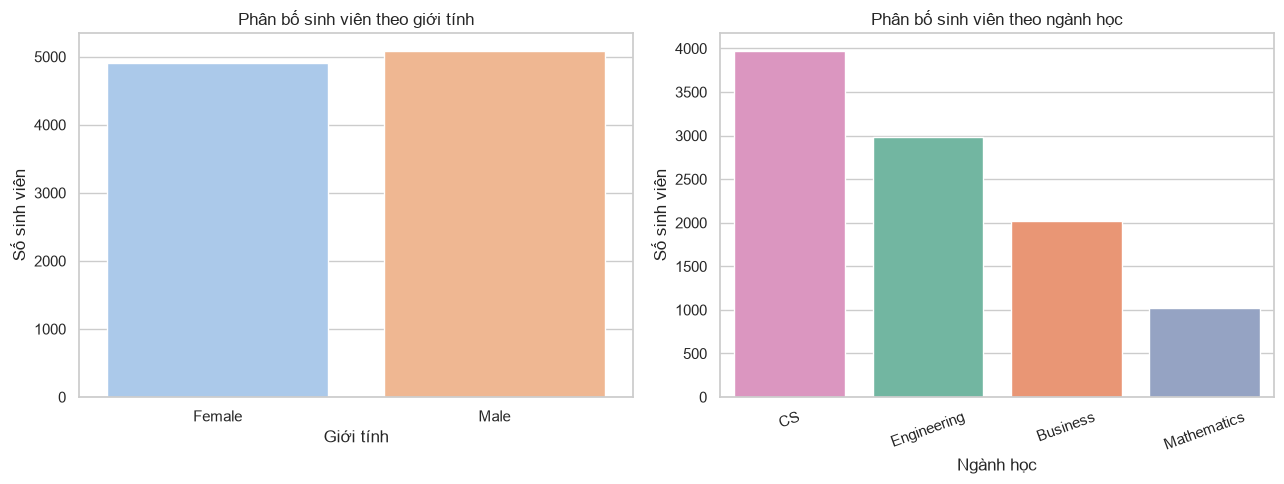

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ giới tính
sns.countplot(
    data=df,
    x="Gender",
    hue="Gender",
    palette="pastel",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Phân bố sinh viên theo giới tính")
axes[0].set_xlabel("Giới tính")
axes[0].set_ylabel("Số sinh viên")

# Biểu đồ ngành học
sns.countplot(
    data=df,
    x="Department",
    hue="Department",
    palette="Set2",
    legend=False,
    order=df["Department"].value_counts().index,
    ax=axes[1]
)
axes[1].set_title("Phân bố sinh viên theo ngành học")
axes[1].set_xlabel("Ngành học")
axes[1].set_ylabel("Số sinh viên")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()



### 6.2. Phân bố các đặc trưng hành vi học tập

Phân tích các thuộc tính:
- Attendance (%): Tỷ lệ chuyên cần.
- Assignments_Avg: Điểm bài tập trung bình.
- Quizzes_Avg: Điểm kiểm tra ngắn.
- Participation_Score: Mức độ tham gia.
- Projects_Score: Điểm dự án.

Các biểu đồ giúp quan sát xu hướng phân bố và sự khác biệt giữa sinh viên.


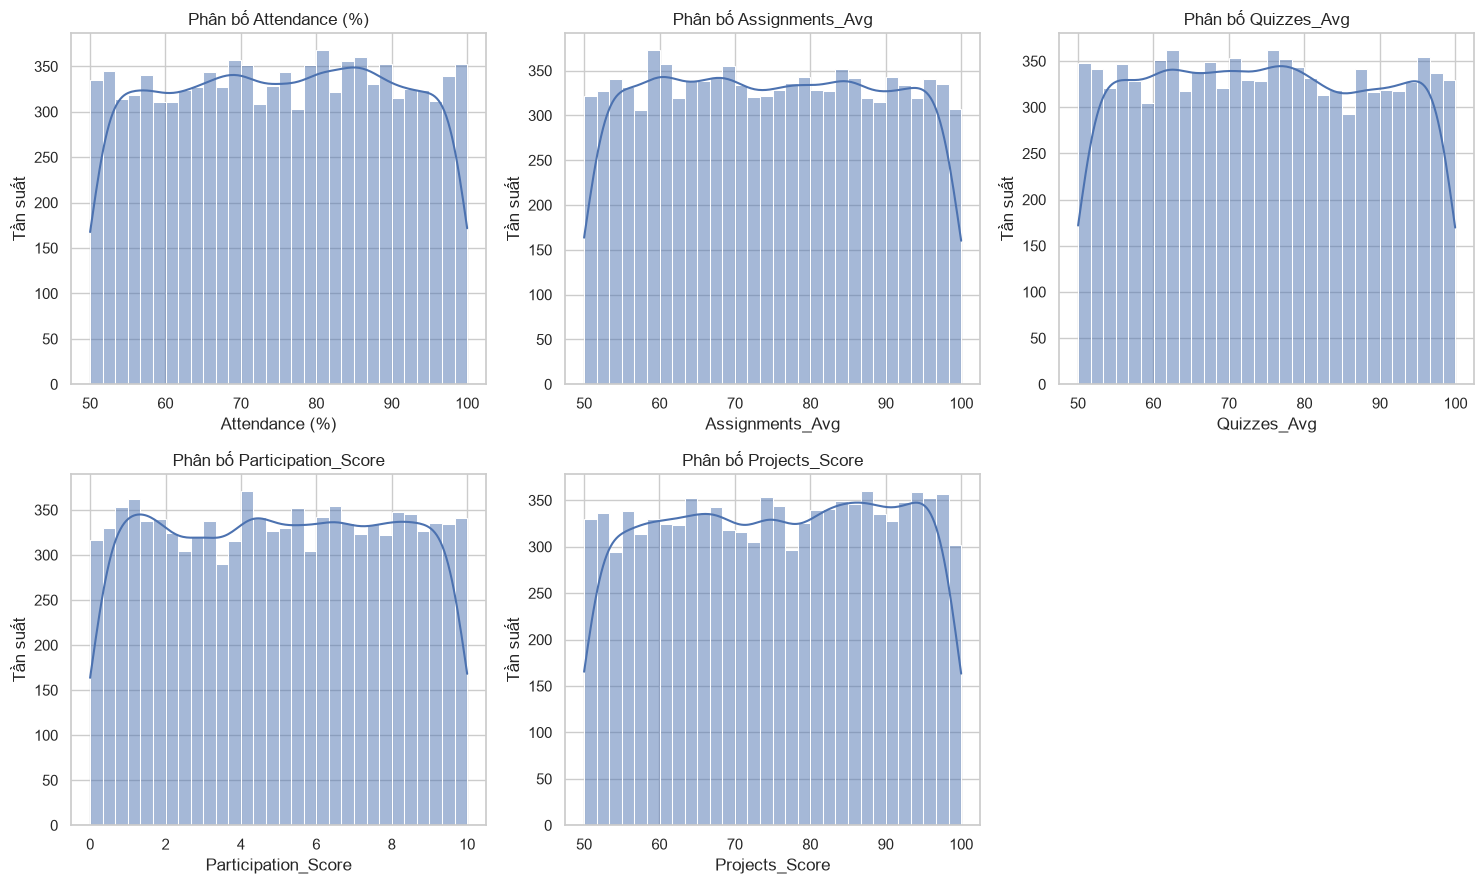

In [15]:

behavior_cols = [
    "Attendance (%)",
    "Assignments_Avg",
    "Quizzes_Avg",
    "Participation_Score",
    "Projects_Score"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(behavior_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Phân bố {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Tần suất")

axes[-1].axis("off")
plt.tight_layout()
plt.show()



### 6.3. Phát hiện giá trị ngoại lệ

Sử dụng Boxplot để quan sát phân bố và các giá trị có khả năng bất thường trong những thuộc tính hành vi học tập.

Các giá trị ngoại lệ sẽ được kiểm tra trước khi quyết định xử lý, không tự động xóa.


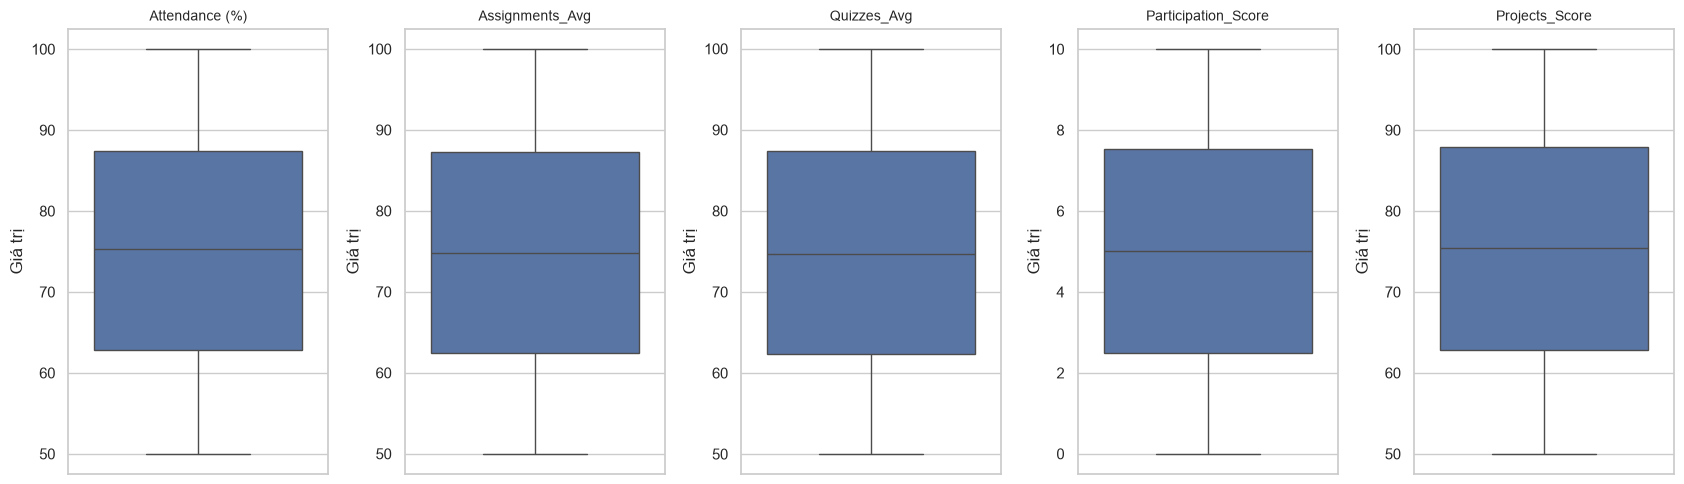

In [16]:

fig, axes = plt.subplots(1, 5, figsize=(17, 5))

for i, col in enumerate(behavior_cols):
    sns.boxplot(
        y=df[col],
        ax=axes[i]
    )
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel("Giá trị")

plt.tight_layout()
plt.show()



### 6.4. Phân tích tương quan giữa các đặc trưng

Sử dụng hệ số tương quan Pearson để đánh giá mối liên hệ tuyến tính giữa các thuộc tính hành vi học tập và kết quả học tập.

Mục đích:
- Phát hiện các thuộc tính có mức tương quan cao.
- Hỗ trợ lựa chọn đặc trưng cho K-Means.
- Tìm hiểu mối liên hệ giữa hành vi và kết quả học tập.


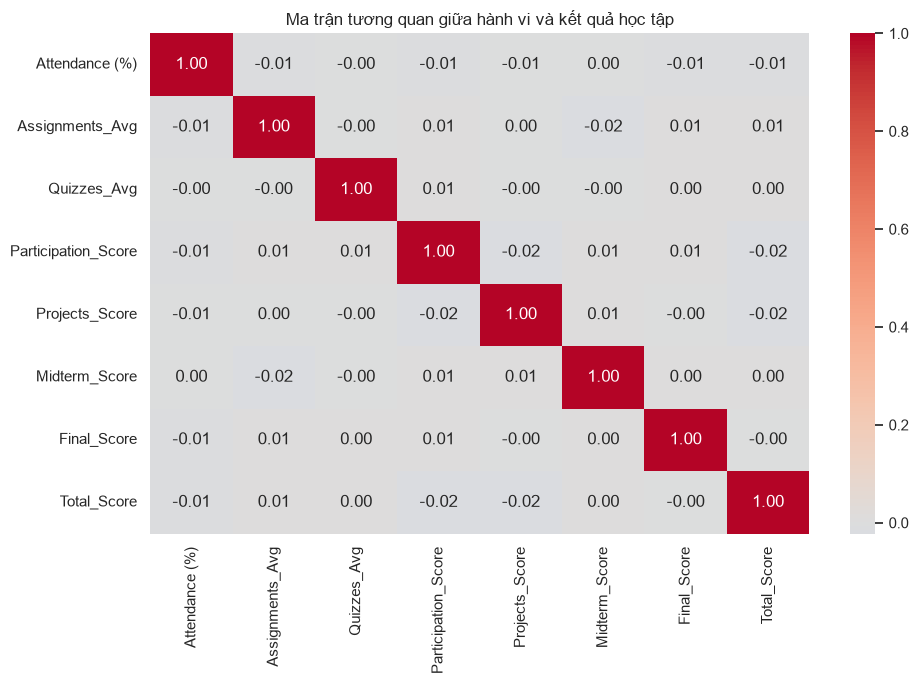

In [17]:

corr_cols = behavior_cols + [
    "Midterm_Score",
    "Final_Score",
    "Total_Score"
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Ma trận tương quan giữa hành vi và kết quả học tập")
plt.tight_layout()
plt.show()



## 7. Đề xuất đặc trưng cho mô hình K-Means

Dựa trên mục tiêu phân nhóm sinh viên theo hành vi học tập, nhóm đề xuất sử dụng các thuộc tính:

1. Attendance (%)
2. Assignments_Avg
3. Quizzes_Avg
4. Participation_Score
5. Projects_Score

Các thuộc tính Student_ID, First_Name và Last_Name chỉ phục vụ định danh, không đưa vào mô hình.

Các thuộc tính về điểm thi và Total_Score được giữ lại để phân tích kết quả học tập sau phân nhóm.

Bộ đặc trưng trên là phương án ban đầu. Thành viên B sẽ tiếp tục kiểm tra tương quan, chuẩn hóa dữ liệu và đánh giá số cụm bằng Elbow và Silhouette trước khi chốt mô hình.
